# 생존분석 통계 모의 풀이

창작 합성 자료입니다. 출제 확인 유형과 확장 연습의 구분은 README를 참고하세요. 노트북의 현재 폴더에서 실행합니다. Python 3.12 실행 환경은 requirements-py312.txt에 고정합니다. 각 문항의 선택 근거·가설은 설명 셀, 실제 계산값·기각 여부는 바로 아래 실행 출력과 실행결과/답안수치.json에 있습니다.

In [1]:

from pathlib import Path
from itertools import combinations
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sys
from pathlib import Path
repo=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'src/Recipes').is_dir())
sys.path.insert(0,str(repo))
from src.stats.survival.kaplan_meier import run_kaplan_meier
from src.stats.survival.rmst import run_rmst
from src.stats.survival.logrank import run_logrank
from src.stats.survival.cox import run_cox

def km_at(km,t):
    return float(np.r_[1.,km.survival][np.searchsorted(km.times,t,side='right')])

def plot_km(km,ax):
    times=np.r_[0.,km.times]; values=np.r_[1.,km.survival]
    line=ax.step(times,values,where='post',label=km.parameters['label'])[0]
    ax.fill_between(times,np.r_[1.,km.confidence_lower],np.r_[1.,km.confidence_upper],step='post',alpha=.15,color=line.get_color())
    mask=km.censored>0;ax.plot(km.times[mask],km.survival[mask],'+',color=line.get_color())
    ax.legend()

def add_risk_counts(kms,ax):
    ticks=[0,10,20,30,40]
    rows=[];labels=[]
    for g,km in kms.items():
        removed=km.events+km.censored
        rows.append([str(int(km.sample_size-removed[km.times<t].sum())) for t in ticks]);labels.append(g)
    table=ax.table(cellText=rows,rowLabels=labels,colLabels=ticks,loc='bottom',bbox=[0,-.5,1,.23])
    table.auto_set_font_size(False);table.set_fontsize(8)
ALPHA=.05
results=[]
def record(question,**kwargs):
    results.append(dict(question=question,**kwargs))
def holm(p):
    p=np.asarray(p,dtype=float);order=np.argsort(p);s=p[order]
    out=np.empty(len(p));out[order]=np.minimum(1,np.maximum.accumulate((len(p)-np.arange(len(p)))*s))
    return out.tolist()
def report(question,method,H0,H1,stat,p,df,evidence,adjusted=None):
    used=float(p) if adjusted is None else float(adjusted)
    reject=used<ALPHA
    conclusion=evidence+('가 있다.' if reject else '가 충분하지 않다.')
    row=dict(method=method,H0=H0,H1=H1,statistic=float(stat),p_value=float(p),df=df,
             alpha=ALPHA,reject_H0=bool(reject),conclusion=conclusion)
    if adjusted is not None:row['p_holm']=float(adjusted)
    record(question,**row);display(pd.DataFrame([row]))
supplier=pd.read_csv('data/supplier.csv')
subscription=pd.read_csv('data/subscription.csv')
equipment=pd.read_csv('data/equipment.csv')


## 1. 공급 장비의 보증기간 검토

품질팀은 공급사 A·B 장비를 설치한 날부터 최초 고장 또는 관찰 종료까지 추적했다. 장비별 관측은 독립이며, 관찰 종료 시점은 고장시간과 독립이라고 가정한다. time은 개월, event=1은 최초 고장, event=0은 그때까지 고장이 관찰되지 않은 우측 중도절단이다. 모두 설치일부터 관찰했으며 경쟁사건·재발 고장은 없다. 같은 시점의 고장과 관찰 종료는 해당 시점 직전 위험집합에 함께 포함한다. 모든 소문항은 같은 자료를 사용한다.

### 1-1

**문제 (3점)** 관측 단위·시작점·관심 사건을 정의하고 event=0의 의미를 설명하시오. 이 관측을 삭제하거나 정상 수명으로 취급한 평균 비교가 왜 부적절한지 설명하시오.

**선택 근거·가정·해석**

장비 한 대가 단위이고 설치일부터 최초 고장까지의 시간이 관심 변수다. event=0은 종료 시점까지의 무고장만 알려준다. 그 시점이 실제 수명이 아니므로 삭제하면 선택 편향, 고장 처리하면 하향 왜곡을 만들 수 있다. 독립적/비정보적 중도절단이 핵심 작업 가정이다.

In [2]:

display(supplier.groupby('group').agg(n=('event','size'), failures=('event','sum')))
print('우측 중도절단: 실제 수명은 기록된 종료 시점보다 길다. event=0은 고장 아님.')


,n,failures
group,,
A,16,9
B,16,4


우측 중도절단: 실제 수명은 기록된 종료 시점보다 길다. event=0은 고장 아님.


### 1-2

**문제 (4점)** 공급사 A의 각 관찰 시점 직전 위험집합 크기, 고장 수, 관찰 종료 수를 표로 만들고, 중도절단을 반영하는 비모수적 생존함수 추정 방법을 선택하시오. 12개월의 계산을 손계산과 코드로 대조하시오.

**선택 근거·가정·해석**

Kaplan-Meier 곱한계 추정을 선택한다. 각 고장 시점에서 S(t)=이전 S×(1-d/n)이며 중도절단은 그 이후 위험집합만 줄인다. 12개월 직전 A의 n=15, d=1, c=1이고 S(12)=(15/16)×(14/15)=0.875다. 동시 고장·절단 순서를 지문의 규약과 일치시킨다.

In [3]:

a = supplier[supplier.group=='A']
km_a = run_kaplan_meier(a.time,a.event,overrides={'label':'A'})
display(pd.DataFrame(dict(time=km_a.times,at_risk=km_a.at_risk,observed=km_a.events,censored=km_a.censored)))
hand12 = (15/16)*(14/15)
assert np.isclose(km_at(km_a,12), hand12)
print('A: n(12)=15, d(12)=1, c(12)=1, S(12)=',hand12)


,time,at_risk,observed,censored
0,8.0,16,1,0
1,12.0,15,1,1
2,16.0,13,1,0
3,20.0,12,1,1
4,24.0,10,1,0
5,25.0,9,0,1
6,28.0,8,1,0
7,30.0,7,1,0
8,32.0,6,0,1
9,35.0,5,1,0


A: n(12)=15, d(12)=1, c(12)=1, S(12)= 0.875


### 1-3

**문제 (4점)** 공급사별 25·30·35개월 생존확률과 해당 시점까지 최초 고장이 발생할 누적확률을 구하시오. 25개월을 넘겨 작동한 A 장비가 35개월도 넘겨 작동할 조건부 확률을 계산하고, 누적확률과 순간 위험률을 구분하시오.

**선택 근거·가정·해석**

F(t)=1-S(t)는 t개월까지 고장이 발생할 누적확률이며 순간 위험률이 아니다. 조건부 확률은 S(35)/S(25)다. 사건 시점에서는 우연속 계단값을 사용하고 S(25)>0임을 확인한다.

In [4]:

kms = {}
rows = []
for g, d in supplier.groupby('group'):
    km = run_kaplan_meier(d.time,d.event,overrides={'label':str(g)})
    kms[g] = km
    for t in [25,30,35]:
        s = float(km_at(km,t)); rows.append(dict(group=g,month=t,S=s,F=1-s))
probabilities = pd.DataFrame(rows)
display(probabilities)
conditional = float(km_at(kms['A'],35)/km_at(kms['A'],25))
print('P(T>35 | T>25), A =',conditional)
record('1-3', probabilities=rows, conditional_A=conditional)


,group,month,S,F
0,A,25,0.666346,0.333654
1,A,30,0.499760,0.500240
2,A,35,0.399808,0.600192
3,B,25,0.855556,0.144444
4,B,30,0.760494,0.239506
5,B,35,0.633745,0.366255


P(T>35 | T>25), A = 0.6


### 1-4

**문제 (4점)** 공급사별 생존곡선·95% 점별 신뢰구간·중도절단 표시·위험집합 수를 제시하고 중앙 생존시간을 구하시오. 관찰 중 생존확률이 0.5 이하로 내려가지 않은 집단과 관찰 범위 밖의 60개월 수명을 어떻게 보고할지 설명하시오.

**선택 근거·가정·해석**

그림은 우측 중도절단 표시와 Greenwood log-log 점별 신뢰구간, 시점별 위험집합을 포함한다. 곡선이 0.5 이하에 도달하지 않으면 중앙수명 미도달로 보고한다. 60개월은 두 집단 최대 관찰기간 밖이므로 마지막 계단값을 외삽 근거로 제시하지 않는다. 신뢰구간은 전체 곡선의 동시 신뢰대역이 아니다.

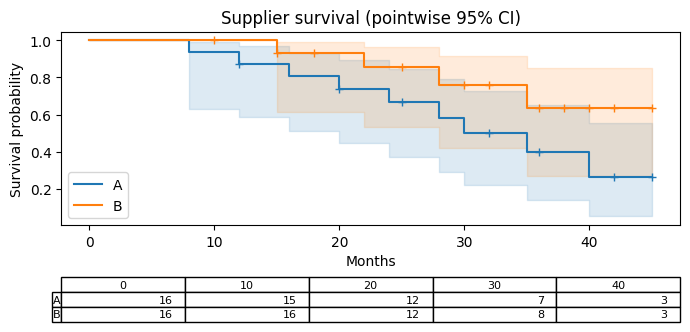

Median (None = not reached): {'A': 30.0, 'B': None}
60개월: 관찰 범위 밖으로 추정 보고하지 않는다.


In [5]:

fig, ax = plt.subplots(figsize=(7,4))
for km in kms.values(): plot_km(km,ax)
add_risk_counts(kms,ax)
ax.set(xlabel='Months',ylabel='Survival probability',title='Supplier survival (pointwise 95% CI)')
plt.tight_layout(); plt.show()
medians = {g: (float(k.median_survival_time) if k.median_survival_time is not None else None) for g,k in kms.items()}
print('Median (None = not reached):', medians)
print('60개월: 관찰 범위 밖으로 추정 보고하지 않는다.')
record('1-4', median_months=medians, outside_followup_60_months='not estimated')


### 1-5

**문제 (5점)** 공급사에 따라 전체 생존분포가 다른지 유의수준 5%에서 판단하시오. 적절한 검정과 근거·가정·귀무가설·대립가설·통계량·자유도·p-value·기각 여부 및 보증정책 관점의 결론을 제시하시오. 작은 표본과 곡선 교차가 해석에 주는 한계를 설명하시오.

**선택 근거·가정·해석**

두 독립 집단의 우측 중도절단 생존분포 비교에 로그순위 검정을 선택한다. H0: 모든 t에서 S_A(t)=S_B(t), H1: 적어도 어떤 t에서 다르다. 독립성·비정보적 중도절단과 충분한 사건 수가 필요하다. 비례위험에서 검정력이 좋고 교차 시 차이를 놓칠 수 있으나 교차 자체가 영가설 하 크기를 자동으로 무효화하는 것은 아니다. 소표본의 점근 p-value를 신중히 해석한다.

In [6]:

b = supplier[supplier.group=='B']
lr = run_logrank(supplier.time,supplier.event,supplier.group)
report('1-5','Log-rank','S_A(t)=S_B(t) for all t','different for some t',lr.statistic,lr.p_value,1,
       '공급사별 전체 생존분포가 다르다는 근거')
print('생존분포 차이는 원인 효과나 특정 보증기간의 경제적 최적성을 증명하지 않는다.')


,method,H0,H1,statistic,p_value,df,alpha,reject_H0,conclusion
0,Log-rank,S_A(t)=S_B(t) for all t,different for some t,2.461125,0.116695,1,0.05,False,공급사별 전체 생존분포가 다르다는 근거가 충분하지 않다.


생존분포 차이는 원인 효과나 특정 보증기간의 경제적 최적성을 증명하지 않는다.


## 2. 서비스 정책별 유지기간 평가

서비스팀은 가입 시점 정책 A·B·C에 따른 최초 해지까지의 기간을 비교한다. 독립 가입자이며 time은 개월, event=1은 최초 해지, event=0은 행정적 관찰 종료다. 관찰 종료는 해지시간과 독립이고 시작 시점의 지연 진입은 없다. 정책은 무작위 배정되지 않았다. 사전에 전체 차이 검정 후 필요 시 세 쌍을 모두 비교하고, 비교군 전체 오류율을 5%로 관리하기로 했다. 비교할 시점 24개월과 검정 절차는 자료 확인 전에 정했다.

### 2-1

**문제 (4점)** 집단별 표본 수·사건 수·중도절단 비율·최대 관찰기간을 제시하고 생존곡선을 그리시오. 각 집단의 24개월 미해지 확률을 추정하되, 단순 잔존 고객 비율과 구분하시오.

**선택 근거·가정·해석**

각 가입자의 추적 길이가 다르므로 단순 잔존 비율은 동일한 24개월 생존확률이 아니다. 집단별 Kaplan-Meier 추정과 위험집합을 사용한다.

,n,events,max_time
group,,,
A,80,73,35.792929
B,80,60,35.891563
C,80,43,35.561564


group
A    0.0875
B    0.2500
C    0.4625
Name: censor_fraction, dtype: float64

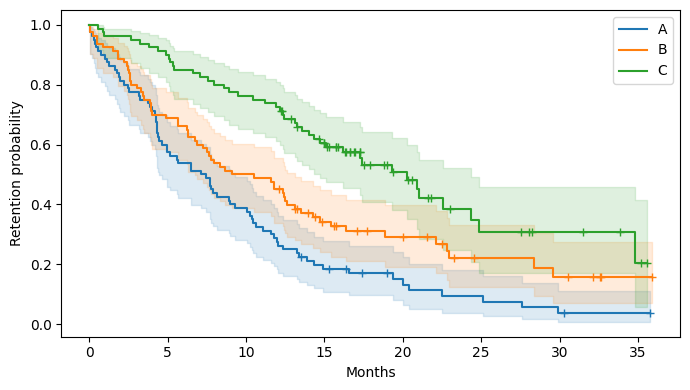

S(24): {'A': 0.09436274509803919, 'B': 0.21944678593282868, 'C': 0.3853825761205613}


In [7]:

display(subscription.groupby('group').agg(n=('event','size'),events=('event','sum'),max_time=('time','max')))
display(subscription.groupby('group').event.apply(lambda x:1-x.mean()).rename('censor_fraction'))
sub_kms = {}
fig,ax = plt.subplots(figsize=(7,4))
for g,d in subscription.groupby('group'):
    k = run_kaplan_meier(d.time,d.event,overrides={'label':str(g)});sub_kms[g]=k
    plot_km(k,ax)
ax.set(xlabel='Months',ylabel='Retention probability');plt.tight_layout();plt.show()
retention24={g:km_at(k,24) for g,k in sub_kms.items()}
print('S(24):',retention24);record('2-1',retention24=retention24)


### 2-2

**문제 (5점)** 세 정책의 전체 유지기간 분포가 같은지 평가할 방법을 선택하시오. 귀무·대립가설, 가정, 통계량·자유도·p-value·기각 여부와 업무 결론을 제시하시오. 전체 검정만으로 어느 두 정책이 다른지 알 수 있는지도 설명하시오.

**선택 근거·가정·해석**

세 독립 집단의 전체 곡선 비교에 다집단 로그순위 검정을 사용한다. H0: 세 생존함수가 모두 같다. H1: 적어도 하나 다르다. 자유도는 2다. 전체 기각은 모든 쌍이 다름을 뜻하지 않는다. 정책은 비무작위이므로 연관성만 판단한다.

In [8]:

overall = run_logrank(subscription.time,subscription.event,subscription.group)
report('2-2','Multivariate log-rank','S_A=S_B=S_C for all t','at least one differs',
       overall.statistic,overall.p_value,2,'정책별 전체 유지기간 분포가 다르다는 근거')


,method,H0,H1,statistic,p_value,df,alpha,reject_H0,conclusion
0,Multivariate log-rank,S_A=S_B=S_C for all t,at least one differs,33.085125,6.541184e-08,2,0.05,True,정책별 전체 유지기간 분포가 다르다는 근거가 있다.


### 2-3

**문제 (5점)** 앞서 정한 절차에 따라 후속 비교 필요 여부를 판단하시오. 필요하면 세 쌍의 원 p-value와 가족단위 오류율을 통제한 보정 p-value, 쌍별 가설·기각 여부·결론을 보고하시오. 가장 작은 p-value만 골라 보고하는 문제를 설명하시오.

**선택 근거·가정·해석**

전체 검정이 기각되면 미리 정한 세 쌍 모두를 비교하고 Holm 방식으로 가족단위 오류율을 통제한다. 쌍별 H0는 두 생존함수 동일, H1은 일부 시점에서 차이. 보정 p-value로 판단하며, 기각하지 못함은 동일성의 증명이 아니다.

In [9]:

if overall.p_value < ALPHA:
    pairs=[]
    for g,h in combinations(sorted(subscription.group.unique()),2):
        d=subscription[subscription.group==g];e=subscription[subscription.group==h]
        pair_data=subscription[subscription.group.isin([g,h])]
        r=run_logrank(pair_data.time,pair_data.event,pair_data.group)
        pairs.append(dict(pair=g+'-'+h,statistic=float(r.statistic),p_value=float(r.p_value)))
    adj=holm([x['p_value'] for x in pairs])
    for row,padj in zip(pairs,adj):
        report('2-3','Pairwise log-rank '+row['pair'],'S_left=S_right for all t','different for some t',
               row['statistic'],row['p_value'],1,'해당 두 정책의 생존분포가 다르다는 근거',padj)
    display(pd.DataFrame(pairs).assign(p_holm=adj,reject=np.array(adj)<ALPHA))
else:
    print('전체 검정 비기각: 사전 규칙에 따라 후속 비교하지 않는다.')


,method,H0,H1,statistic,p_value,df,alpha,reject_H0,conclusion,p_holm
0,Pairwise log-rank A-B,S_left=S_right for all t,different for some t,5.952304,0.014698,1,0.05,True,해당 두 정책의 생존분포가 다르다는 근거가 있다.,0.014698


,method,H0,H1,statistic,p_value,df,alpha,reject_H0,conclusion,p_holm
0,Pairwise log-rank A-C,S_left=S_right for all t,different for some t,35.227115,2.934098e-09,1,0.05,True,해당 두 정책의 생존분포가 다르다는 근거가 있다.,8.802294e-09


,method,H0,H1,statistic,p_value,df,alpha,reject_H0,conclusion,p_holm
0,Pairwise log-rank B-C,S_left=S_right for all t,different for some t,10.397222,0.001262,1,0.05,True,해당 두 정책의 생존분포가 다르다는 근거가 있다.,0.002524


,pair,statistic,p_value,p_holm,reject
0,A-B,5.952304,1.469806e-02,1.469806e-02,True
1,A-C,35.227115,2.934098e-09,8.802294e-09,True
2,B-C,10.397222,1.262050e-03,2.524100e-03,True


### 2-4

**문제 (6점)** 사전에 정한 24개월까지 생존곡선 아래 면적을 계산하여 집단별 평균 미해지 유지기간을 요약하시오. 이 값과 중앙 생존시간의 차이를 설명하시오. 곡선 교차 시 전체 검정 하나와 단일 위험비만으로 정책을 추천하기 어려운 이유, 추가 검증과 인과 해석의 한계를 서술하시오. 이 소문항은 구간 추정이나 가설검정을 요구하지 않는다.

**선택 근거·가정·해석**

24개월 제한평균생존시간(RMST)은 0~24개월 생존곡선 아래 면적으로 모든 집단에 같은 제한 시점을 적용한다. 중앙수명은 S(t)가 0.5 이하가 되는 최초 시점이다. 여기서 RMST 차이는 기술통계이며 유의성은 주장하지 않는다. 교차 곡선은 시간별 차이가 상쇄될 수 있어 사전 지정 RMST·시간구간별 효과 등 추가 분석을 고려하되 결과를 보고 유리한 검정을 선택하지 않는다.

In [10]:

rmst={g:run_rmst(d.time,d.event,overrides={'tau':24}).estimate for g,d in subscription.groupby('group')}
print('RMST(0,24), months:',rmst)
record('2-4',rmst_24=rmst,meaning='descriptive only; no test/CI requested')
print('비무작위 정책: 교란·비용·고객구성·후속 표본을 검토해야 한다.')


RMST(0,24), months: {'A': 8.977220098296566, 'B': 11.835493903087466, 'C': 16.790030873846746}
비무작위 정책: 교란·비용·고객구성·후속 표본을 검토해야 한다.


## 3. 설비 상태를 반영한 고장 위험 평가

운영팀은 장비별 최초 고장까지의 time(개월)과 event(1=고장, 0=행정적 종료)를 기록했다. temperature10은 (온도-60)/10, load10은 (부하율-70)/10, new_part는 신규 부품 사용=1·기존=0이다. 시작 시점에 측정한 세 변수를 모두 사용하고 식별자 id는 제외한다. 장비 관측은 독립, 지연 진입·경쟁사건은 없고, 공변량 조건부 중도절단은 비정보적이라고 가정한다. 연속 변수의 로그 위험에 대한 선형성은 작업 가정이다. 진단용 시간변환은 rank로 사전 지정하고 세 변수 진단의 가족단위 오류율을 5%로 관리한다.

### 3-1

**문제 (4점)** 온도·부하를 보정하며 신규 부품과 고장 발생 위험의 관계를 설명할 회귀 방법을 선택하시오. 모형식·기준집단·계수 단위·핵심 가정과 사건 수를 제시하고 세 변수를 모두 넣어 적합하시오.

**선택 근거·가정·해석**

Cox 비례위험 모형 h(t|x)=h0(t)exp(β1 temperature10+β2 load10+β3 new_part)을 선택한다. 기준은 온도60도·부하70%·기존 부품이다. temperature10·load10 한 단위는 각각 10도·10%p다. 모형은 비례위험·로그 위험 선형성·독립성·조건부 비정보적 중도절단을 가정한다. 단순 고장여부 분류는 관찰기간 차이를 반영하지 못한다.

In [11]:

xcols=['temperature10','load10','new_part']
model_data=equipment[['time','event']+xcols].copy()
prediction_profiles=pd.DataFrame({'temperature10':[1.,1.],'load10':[1.,1.],'new_part':[0,1]},index=['old','new'])
cox_result=run_cox(model_data,new_data=prediction_profiles,overrides={'prediction_times':[24.]})
cph=cox_result.model
print('장비 수:',len(model_data),'사건 수:',int(model_data.event.sum()))
display(cox_result.coefficients[['coef','se(coef)','exp(coef)','p']])


장비 수: 360 사건 수: 212


,coef,se(coef),exp(coef),p
covariate,,,,
temperature10,0.692527,0.082870,1.998759,6.443622e-17
load10,0.479719,0.071066,1.615621,1.475392e-11
new_part,-0.684274,0.143866,0.504456,1.971356e-06


### 3-2

**문제 (5점)** 각 계수의 귀무가설·대립가설을 설정하고 추정계수·표준오차·위험비·위험비의 95% 신뢰구간·검정통계량·양측 p-value·기각 여부를 보고하시오. 계수별 검정은 개별 5% 탐색 결과로 표시하고 다중검정 한계를 밝히시오. 온도 10도 증가 및 신규 부품의 의미를 위험비와 확률비를 구분해 설명하시오.

**선택 근거·가정·해석**

변수별 H0: βj=0(HR=1), H1: βj≠0. Wald z=β/SE이며 양측 검정이다. HR=exp(β), 95% CI=exp(β±1.96SE)다. 다른 조건이 같은 순간의 위험비이지 누적 고장확률비 또는 생존확률 증가율이 아니다. 세 계수 p값은 개별 탐색 검정이며 가족단위 오류율 통제를 주장하지 않는다.

In [12]:

coef=cox_result.coefficients[['coef','se(coef)','exp(coef)','exp(coef) lower 95%','exp(coef) upper 95%','z','p']]
display(coef)
for name,row in coef.iterrows():
    report('3-2','Cox Wald z: '+name,'beta_'+name+'=0','beta_'+name+' != 0',row['z'],row['p'],None,
           name+'과 조건부 고장 위험의 연관성이 있다는 근거')
record('3-2',coefficients=coef.reset_index().to_dict(orient='records'))


,coef,se(coef),exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,z,p
covariate,,,,,,,
temperature10,0.692527,0.082870,1.998759,1.699111,2.351253,8.356811,6.443622e-17
load10,0.479719,0.071066,1.615621,1.405555,1.857083,6.750301,1.475392e-11
new_part,-0.684274,0.143866,0.504456,0.380509,0.668778,-4.756339,1.971356e-06


,method,H0,H1,statistic,p_value,df,alpha,reject_H0,conclusion
0,Cox Wald z: temperature10,beta_temperature10=0,beta_temperature10 != 0,8.356811,6.443622e-17,None,0.05,True,temperature10과 조건부 고장 위험의 연관성이 있다는 근거가 있다.


,method,H0,H1,statistic,p_value,df,alpha,reject_H0,conclusion
0,Cox Wald z: load10,beta_load10=0,beta_load10 != 0,6.750301,1.475392e-11,None,0.05,True,load10과 조건부 고장 위험의 연관성이 있다는 근거가 있다.


,method,H0,H1,statistic,p_value,df,alpha,reject_H0,conclusion
0,Cox Wald z: new_part,beta_new_part=0,beta_new_part != 0,-4.756339,0.000002,None,0.05,True,new_part과 조건부 고장 위험의 연관성이 있다는 근거가 있다.


### 3-3

**문제 (3점)** 온도 70도·부하율 80%인 장비에 대해 기존/신규 부품 사용 시 24개월 생존확률과 누적 고장확률을 예측하시오. 같은 온도·부하 조건의 상대적 위험과 24개월 고장확률비가 같은지 설명하시오. 표본 내 조건부 추정의 한계도 밝히시오.

**선택 근거·가정·해석**

temperature10=1, load10=1로 변환한다. Cox 누적 기준위험을 이용한 생존확률과 1-S(24)를 보고한다. 동일 조건의 위험비 exp(β_new)와 고정 시점의 누적 고장확률비는 일반적으로 다르다. 학습 자료에 적합한 조건부 추정이므로 외부 예측 정확도나 인과 개선율로 해석하지 않는다.

In [13]:

profiles=pd.DataFrame({'temperature10':[1.,1.],'load10':[1.,1.],'new_part':[0,1]},index=['old','new'])
pred=cox_result.predictions.iloc[0]
display(pd.DataFrame({'S24':pred,'F24':1-pred}))
hr=float(np.exp(cph.params_['new_part']))
print('HR new/old:',hr,'F24 new/old:',float((1-pred['new'])/(1-pred['old'])))
record('3-3',S24=pred.to_dict(),HR=hr)


,S24,F24
old,0.107706,0.892294
new,0.324943,0.675057


HR new/old: 0.5044562984657265 F24 new/old: 0.7565407792241408


### 3-4

**문제 (5점)** 각 변수의 상대적 위험이 시간에 따라 일정하다는 가정을 잔차 기반으로 점검하시오. 진단 가설·통계량·원 p-value·세 변수 보정 p-value·판정을 제시하고 잔차 그림을 함께 해석하시오. 기각하지 못한 경우의 표현과 위반 시 대안을 설명하시오.

**선택 근거·가정·해석**

Schoenfeld 잔차 기반 PH 진단의 H0는 해당 계수가 시간에 따라 일정함, H1은 시간에 따라 변함이다. 계수=0 검정과 다르다. rank 시간변환과 세 변수 Holm 보정을 사전에 정했다. 보정 후 비기각은 PH 가정이 증명됐다는 뜻이 아니다. 작은 표본의 검정력, 함수형태 오류도 검토한다. 위반 시 층화·시간상호작용·시간가변 계수 등 대안을 고려한다.

,test_statistic,p,-log2(p),adjusted_p_value,reject_h0,p_holm
load10,0.432630,0.510701,0.969448,0.903131,False,0.903131
new_part,2.190336,0.138879,2.848100,0.416637,False,0.416637
temperature10,0.566720,0.451565,1.146993,0.903131,False,0.903131


,method,H0,H1,statistic,p_value,df,alpha,reject_H0,conclusion,p_holm
0,Schoenfeld rank diagnostic: load10,beta_load10 constant over time,beta_load10 varies with time,0.43263,0.510701,1,0.05,False,load10의 비례위험 가정 위반을 시사하는 근거가 충분하지 않다.,0.903131


,method,H0,H1,statistic,p_value,df,alpha,reject_H0,conclusion,p_holm
0,Schoenfeld rank diagnostic: new_part,beta_new_part constant over time,beta_new_part varies with time,2.190336,0.138879,1,0.05,False,new_part의 비례위험 가정 위반을 시사하는 근거가 충분하지 않다.,0.416637


,method,H0,H1,statistic,p_value,df,alpha,reject_H0,conclusion,p_holm
0,Schoenfeld rank diagnostic: temperature10,beta_temperature10 constant over time,beta_temperature10 varies with time,0.56672,0.451565,1,0.05,False,temperature10의 비례위험 가정 위반을 시사하는 근거가 충분하지 않다.,0.903131


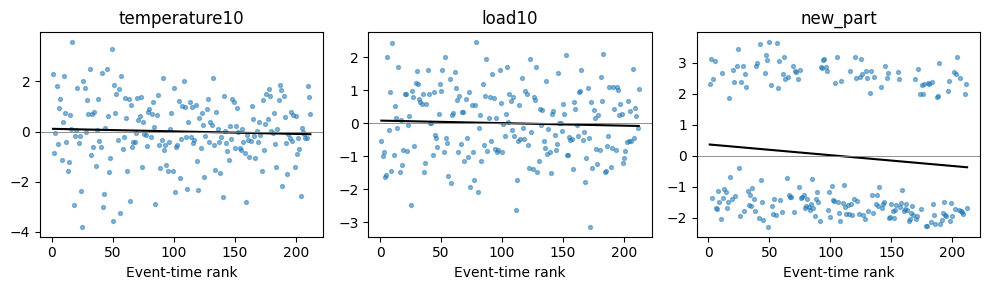

잔차 직선은 시각적 참고선이며 독립적인 확정 검정이 아니다. 비기각은 가정의 증명이 아니다.


In [14]:

ph=cox_result.ph_diagnostics.copy()
ph['p_holm']=ph.adjusted_p_value
display(ph)
for name,row in ph.iterrows():
    report('3-4','Schoenfeld rank diagnostic: '+name,'beta_'+name+' constant over time',
           'beta_'+name+' varies with time',row.test_statistic,row.p,1,
           name+'의 비례위험 가정 위반을 시사하는 근거',row.p_holm)
res=cph.compute_residuals(model_data,kind='scaled_schoenfeld')
rank_time=model_data.loc[res.index,'time'].rank().to_numpy()
fig,axes=plt.subplots(1,3,figsize=(10,3))
for ax,name in zip(axes,xcols):
    ax.scatter(rank_time,res[name],s=8,alpha=.5)
    line=np.polyfit(rank_time,res[name].to_numpy(),1)
    xx=np.array([rank_time.min(),rank_time.max()]);ax.plot(xx,np.polyval(line,xx),color='black')
    ax.axhline(0,color='grey',lw=.6);ax.set(title=name,xlabel='Event-time rank')
plt.tight_layout();plt.show()
print('잔차 직선은 시각적 참고선이며 독립적인 확정 검정이 아니다. 비기각은 가정의 증명이 아니다.')


### 3-5

**문제 (3점)** 신규 부품 도입에 대한 업무 결론을 효과 크기·불확실성·가정 진단과 연결해 작성하시오. 위험비가 1 미만인 것을 생존확률 증가율로 해석하는 오류, 관찰 자료에서 인과 효과를 단정하는 오류, 검정 결과만으로 부품 비용·안전을 결정하는 한계를 설명하시오.

**선택 근거·가정·해석**

실제 추정 HR·CI·계수 p와 PH 진단을 함께 확인해 조건부 연관성을 보고한다. 무작위 배정이 없는 합성 관찰 설계로 비용 절감이나 안전 개선의 인과 효과를 주장할 수 없다. 결측·비선형성·미측정 교란·외부 검증·예방정비에 따른 정보성 절단 가능성을 추가 점검한다.

In [15]:

r=cox_result.coefficients.loc['new_part']
print('신규 부품 HR={:.4f}, 95% CI=({:.4f},{:.4f}), individual p={:.6g}'.format(
    r['exp(coef)'],r['exp(coef) lower 95%'],r['exp(coef) upper 95%'],r['p']))
print('위 수치는 합성 자료의 조건부 연관성이다. 부품 도입은 비용·안전·실험 설계·외부 검증을 추가해 판단한다.')
out=Path('실행결과');out.mkdir(exist_ok=True)
(out/'답안수치.json').write_text(json.dumps(results,ensure_ascii=False,indent=2,allow_nan=False)+'\n',encoding='utf-8')


신규 부품 HR=0.5045, 95% CI=(0.3805,0.6688), individual p=1.97136e-06
위 수치는 합성 자료의 조건부 연관성이다. 부품 도입은 비용·안전·실험 설계·외부 검증을 추가해 판단한다.
